In [5]:
!pip install swig 
!pip install box2d gymnasium

  Using cached swig-4.5.1-py3-none-manylinux_2_12_x86_64.manylinux2010_x86_64.whl.metadata (3.3 kB)
Using cached swig-4.5.1-py3-none-manylinux_2_12_x86_64.manylinux2010_x86_64.whl (1.9 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 11.6 MB/s  0:00:00 eta 0:00:01


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
Training BipedalWalker: 1000008it [15:38, 1065.32it/s]                            


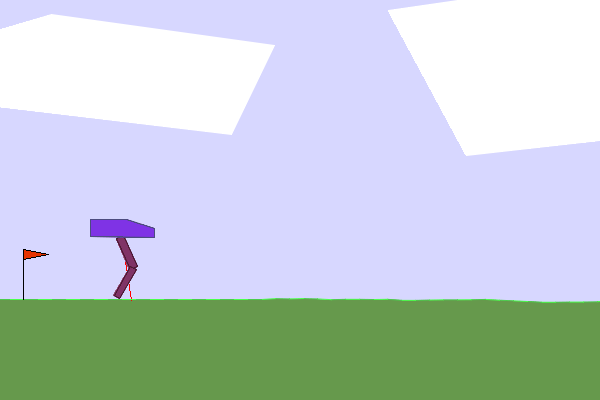

In [6]:
from functools import partial
import imageio
import gymnasium as gym
import jax
import jax.numpy as jnp
import numpy as np
import flax.linen as nn
import flax.serialization
import optax
from IPython.display import Image, display
from tqdm import tqdm

N, STEPS, WARM, B, UPD, CAP = 12, 1_000_000, 10_000, 512, 8, 1_000_000
GAMMA, TAU, LR = 0.99, 0.005, 3e-4


class MLP(nn.Module):
    out: int

    @nn.compact
    def __call__(self, x):
        x = nn.relu(nn.Dense(256)(x))
        x = nn.relu(nn.Dense(256)(x))
        return nn.Dense(self.out)(x)


class Critic(nn.Module):
    @nn.compact
    def __call__(self, o, a):
        x = jnp.concatenate([o, a], -1)
        return jnp.stack([MLP(1)(x)[..., 0], MLP(1)(x)[..., 0]], 0)


env = gym.vector.AsyncVectorEnv(
    [lambda: gym.make("BipedalWalker-v3") for _ in range(N)],
    autoreset_mode=gym.vector.AutoresetMode.SAME_STEP,
)
od, ad = env.single_observation_space.shape[0], env.single_action_space.shape[0]
tgt_ent = -float(ad)

actor, critic = MLP(2 * ad), Critic()
key = jax.random.PRNGKey(0)
key, k1, k2 = jax.random.split(key, 3)
ap = actor.init(k1, jnp.zeros((1, od)))
cp = critic.init(k2, jnp.zeros((1, od)), jnp.zeros((1, ad)))
aopt, copt, lopt = optax.adam(LR), optax.adam(LR), optax.adam(LR)
la0 = jnp.zeros(())
state = dict(
    a=ap,
    c=cp,
    t=cp,
    la=la0,
    ao=aopt.init(ap),
    co=copt.init(cp),
    lo=lopt.init(la0),
    key=key,
)
buf = jnp.zeros((CAP, 2 * od + ad + 2), jnp.float32)


def sample(p, o, k):
    mu, ls = jnp.split(actor.apply(p, o), 2, -1)
    ls = jnp.clip(ls, -5, 2)
    e = jax.random.normal(k, mu.shape)
    u = mu + jnp.exp(ls) * e
    a = jnp.tanh(u)
    lp = (-0.5 * e**2 - ls - 0.9189385).sum(-1)
    lp = lp - (2 * (0.6931472 - u - jax.nn.softplus(-2 * u))).sum(-1)
    return a, lp


@jax.jit
def train(s, buf, size):
    def one(s, _):
        key, k0, k1, k2 = jax.random.split(s["key"], 4)
        b = buf[jax.random.randint(k0, (B,), 0, size)]
        o, a, r, d, n = (
            b[:, :od],
            b[:, od : od + ad],
            b[:, od + ad],
            b[:, od + ad + 1],
            b[:, od + ad + 2 :],
        )
        alpha = jnp.exp(s["la"])
        na, nlp = sample(s["a"], n, k1)
        tq = critic.apply(s["t"], n, na).min(0) - alpha * nlp
        y = jax.lax.stop_gradient(r + GAMMA * (1 - d) * tq)

        def closs(c):
            return ((critic.apply(c, o, a) - y) ** 2).mean(1).sum()

        cg = jax.grad(closs)(s["c"])
        u, co = copt.update(cg, s["co"])
        c = optax.apply_updates(s["c"], u)

        def aloss(p):
            pa, lp = sample(p, o, k2)
            return (alpha * lp - critic.apply(c, o, pa).min(0)).mean(), lp

        (_, lp), ag = jax.value_and_grad(aloss, has_aux=True)(s["a"])
        u, ao = aopt.update(ag, s["ao"])
        ap = optax.apply_updates(s["a"], u)

        lg = jax.grad(
            lambda la: -(la * (jax.lax.stop_gradient(lp) + tgt_ent).mean())
        )(s["la"])
        u, lo = lopt.update(lg, s["lo"])
        la = optax.apply_updates(s["la"], u)

        t = optax.incremental_update(c, s["t"], TAU)
        return (
            dict(a=ap, c=c, t=t, la=la, ao=ao, co=co, lo=lo, key=key),
            None,
        )

    return jax.lax.scan(one, s, None, length=UPD)[0]


@partial(jax.jit, donate_argnums=0)
def add(buf, row, ptr):
    return buf.at[(ptr + jnp.arange(N)) % CAP].set(row)


@jax.jit
def act(p, o, k):
    return sample(p, o, k)[0]


@jax.jit
def act_det(p, o):
    return jnp.tanh(jnp.split(actor.apply(p, o), 2, -1)[0])


obs, _ = env.reset(seed=0)
ptr = size = t = 0

pbar = tqdm(total=STEPS, desc="Training BipedalWalker")
while t < STEPS:
    if t < WARM:
        a = env.action_space.sample()
    else:
        key, k = jax.random.split(key)
        a = np.asarray(act(state["a"], obs.astype(np.float32), k))
    nobs, rew, term, trunc, info = env.step(a)
    real_next = nobs.copy()
    if "final_obs" in info:
        for i in np.where(info["_final_obs"])[0]:
            real_nested = info["final_obs"][i]
            real_next[i] = real_nested
    row = np.concatenate(
        [obs, a, rew[:, None], term[:, None], real_next], 1
    ).astype(np.float32)
    buf = add(buf, row, ptr)
    ptr = (ptr + N) % CAP
    size = min(size + N, CAP)
    obs = nobs

    step_increment = N
    t += step_increment
    pbar.update(step_increment)

    if t >= WARM:
        state = train(state, buf, size)

pbar.close()
env.close()

with open("bipedal_actor.msgpack", "wb") as f:
    f.write(flax.serialization.to_bytes(state["a"]))

renv = gym.make("BipedalWalker-v3", render_mode="rgb_array")
o, _ = renv.reset(seed=1)
frames = []
done = False
while not done:
    a = np.asarray(act_det(state["a"], o[None].astype(np.float32)))[0]
    o, _, te, tr, _ = renv.step(a)
    done = te or tr
    frames.append(renv.render())
renv.close()
imageio.mimsave("bipedal.gif", frames[::2], fps=30, loop=0)

display(Image(filename="bipedal.gif"))